<a href="https://colab.research.google.com/github/ZIZOUTOUMOU/LAB02-AdvDB/blob/main/Copy_of_TP02_BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP02 – Working with Big Data Files (5GB+)
**Pandas OOM → Pandas chunking → Dask (lazy + parallel)**

Run the cells top to bottom in Google Colab.
**Tip:** Colab free = ~12 GB RAM, so a 5 GB CSV (which expands 2–4x in pandas) will exceed memory.

In [ ]:
!pip -q install "dask[complete]" psutil pyarrow matplotlib graphviz

## 0. Dataset – real data from a website
**NYC Yellow Taxi Trip Records** – official open data from the NYC Taxi & Limousine Commission (TLC), hosted on a public CDN:
`https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_YYYY-MM.parquet`
(info page: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

TLC only publishes **Parquet** (~50 MB/month, ~3M trips). To get a **5GB+ CSV** as the TP requires, the notebook downloads month after month (from 2023-01) and streams each file into one big CSV (batch by batch, so conversion itself uses little RAM) until the target size is reached.

In [ ]:
import os, time, threading, gc, subprocess, sys, textwrap, urllib.request
import numpy as np, pandas as pd, psutil
import pyarrow.parquet as pq

TARGET_GB = 6                            # stop adding months once the CSV reaches this size
START     = (2023, 1)                    # first month to download
CSV_PATH  = "/content/nyc_taxi_big.csv"
VALUE_COL = "fare_amount"                # numeric column
GROUP_COL = "PULocationID"               # pickup zone id (int) for group-by
CHUNK     = 100_000                      # rows per chunk (Task 2)
COLS = ["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count",
        "trip_distance", "RatecodeID", "PULocationID", "DOLocationID", "payment_type",
        "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount", "total_amount"]

In [ ]:
URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{y}-{m:02d}.parquet"

def fetch(url, dest):
    urllib.request.urlretrieve(url, dest)

def build_big_csv(path, target_gb, start=START):
    if os.path.exists(path) and os.path.getsize(path) >= target_gb * 1024**3:
        print("Already built."); return
    if os.path.exists(path): os.remove(path)
    y, m, first = start[0], start[1], True
    while not os.path.exists(path) or os.path.getsize(path) < target_gb * 1024**3:
        url, tmp = URL.format(y=y, m=m), "/content/tmp.parquet"
        t0 = time.time(); fetch(url, tmp)
        for batch in pq.ParquetFile(tmp).iter_batches(batch_size=500_000, columns=COLS):
            batch.to_pandas().to_csv(path, mode="w" if first else "a", header=first, index=False)
            first = False
        os.remove(tmp)
        print(f"{y}-{m:02d} done in {time.time()-t0:.0f}s | CSV = {os.path.getsize(path)/1024**3:.2f} GB")
        m += 1
        if m == 13: y, m = y + 1, 1

build_big_csv(CSV_PATH, TARGET_GB)
print("File size: %.2f GB" % (os.path.getsize(CSV_PATH) / 1024**3))
print(open(CSV_PATH).readline())

2023-01 done in 57s | CSV = 0.26 GB
2023-02 done in 46s | CSV = 0.50 GB
2023-03 done in 49s | CSV = 0.78 GB
2023-04 done in 52s | CSV = 1.04 GB
2023-05 done in 53s | CSV = 1.33 GB
2023-06 done in 48s | CSV = 1.60 GB
2023-07 done in 44s | CSV = 1.84 GB
2023-08 done in 43s | CSV = 2.07 GB
2023-09 done in 46s | CSV = 2.30 GB
2023-10 done in 55s | CSV = 2.59 GB
2023-11 done in 51s | CSV = 2.86 GB
2023-12 done in 55s | CSV = 3.13 GB
2024-01 done in 43s | CSV = 3.38 GB
2024-02 done in 45s | CSV = 3.62 GB
2024-03 done in 55s | CSV = 3.91 GB
2024-04 done in 57s | CSV = 4.20 GB
2024-05 done in 59s | CSV = 4.50 GB
2024-06 done in 58s | CSV = 4.79 GB
2024-07 done in 48s | CSV = 5.04 GB
2024-08 done in 46s | CSV = 5.28 GB
2024-09 done in 59s | CSV = 5.58 GB
2024-10 done in 61s | CSV = 5.89 GB
2024-11 done in 57s | CSV = 6.19 GB
File size: 6.19 GB
VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta

## Profiling helper
Samples the RSS memory of the process (and its children) every 0.1 s in a background thread and records the **peak**.

In [ ]:
class Profiler:
    def __init__(self, interval=0.1):
        self.interval, self.peak = interval, 0
    def _rss(self):
        p = psutil.Process(); total = p.memory_info().rss
        for c in p.children(recursive=True):
            try: total += c.memory_info().rss
            except psutil.Error: pass
        return total
    def _run(self):
        while not self._stop:
            self.peak = max(self.peak, self._rss()); time.sleep(self.interval)
    def __enter__(self):
        gc.collect(); self.base = self._rss(); self.peak = self.base
        self._stop = False; self.t0 = time.perf_counter()
        self.th = threading.Thread(target=self._run, daemon=True); self.th.start(); return self
    def __exit__(self, *a):
        self.elapsed = time.perf_counter() - self.t0
        self._stop = True; self.th.join()
        self.peak_mb = self.peak / 1024**2
        self.extra_mb = (self.peak - self.base) / 1024**2

TOTAL_RAM = psutil.virtual_memory().total
print(f"System RAM: {TOTAL_RAM/1024**3:.1f} GB")
results = {}

System RAM: 12.7 GB


## Task 1 – The traditional failure (OOM)
First estimate how much RAM a full `read_csv` needs, using a 100k-row sample.

In [ ]:
file_size = os.path.getsize(CSV_PATH)
sample = pd.read_csv(CSV_PATH, nrows=100_000)
sample_csv_bytes = len(sample.to_csv(index=False).encode())
sample_ram = sample.memory_usage(deep=True).sum()
est_ram = file_size / sample_csv_bytes * sample_ram

print(f"File on disk        : {file_size/1024**3:.2f} GB")
print(f"RAM/disk ratio      : {sample_ram/sample_csv_bytes:.1f}x")
print(f"Estimated RAM needed: {est_ram/1024**3:.1f} GB  vs  available {psutil.virtual_memory().available/1024**3:.1f} GB")
sample.info(memory_usage="deep")

File on disk        : 6.19 GB
RAM/disk ratio      : 2.6x
Estimated RAM needed: 16.3 GB  vs  available 11.2 GB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               100000 non-null  int64  
 1   tpep_pickup_datetime   100000 non-null  object 
 2   tpep_dropoff_datetime  100000 non-null  object 
 3   passenger_count        100000 non-null  float64
 4   trip_distance          100000 non-null  float64
 5   RatecodeID             100000 non-null  float64
 6   PULocationID           100000 non-null  int64  
 7   DOLocationID           100000 non-null  int64  
 8   payment_type           100000 non-null  int64  
 9   fare_amount            100000 non-null  float64
 10  extra                  100000 non-null  float64
 11  mta_tax                100000 non-null  float64
 12  tip_amount             100000 non

A real OOM on Colab kills the whole kernel ("session crashed"), so we first reproduce it **safely**:
a sub-process with a 3 GB address-space limit (`RLIMIT_AS`), which turns the crash into a catchable `MemoryError`.

In [ ]:
LIMIT_GB = 3
script = textwrap.dedent(f'''
    import resource, pandas as pd, psutil, time
    lim = {LIMIT_GB} * 1024**3
    resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    t0 = time.time()
    try:
        df = pd.read_csv("{CSV_PATH}")
        print("Loaded?!", df.shape)
    except MemoryError as e:
        rss = psutil.Process().memory_info().rss / 1024**3
        print("MemoryError caught:", repr(e))
        print(f"RSS at failure: {{rss:.2f}} GB after {{time.time()-t0:.1f}}s")
''')
with Profiler() as p1:
    out = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True)
print(out.stdout, out.stderr[-500:])
results["Standard Pandas"] = dict(time=None, peak_mb=LIMIT_GB*1024, status="OOM (MemoryError)")

MemoryError caught: MemoryError()
RSS at failure: 1.84 GB after 45.7s
 


In [ ]:
# OPTIONAL - the real thing. WARNING: will probably crash the Colab session.
RUN_REAL_CRASH = False
if RUN_REAL_CRASH:
    df = pd.read_csv(CSV_PATH)   # watch RAM in the top-right Colab "Resources" panel

## Task 2 – Pandas chunking (stream processing)
Read 100,000 rows at a time and keep only **incremental aggregates** (count, sum, min, max, per-group sum/count). Memory stays ~constant.

In [ ]:
def pandas_chunking(path, chunk=CHUNK):
    n = 0; s = 0.0; mn = np.inf; mx = -np.inf
    g_sum = pd.Series(dtype="float64"); g_cnt = pd.Series(dtype="int64")
    for df in pd.read_csv(path, usecols=[VALUE_COL, GROUP_COL], chunksize=chunk,
                          dtype={VALUE_COL: "float32", GROUP_COL: "int32"}):
        v = df[VALUE_COL]
        n += v.count(); s += v.sum(); mn = min(mn, v.min()); mx = max(mx, v.max())
        grp = df.groupby(GROUP_COL, observed=True)[VALUE_COL]
        g_sum = g_sum.add(grp.sum(), fill_value=0)
        g_cnt = g_cnt.add(grp.count(), fill_value=0)
    return dict(rows=n, sum=s, mean=s / n, min=mn, max=mx, group_mean=(g_sum / g_cnt))

with Profiler() as p2:
    r_pd = pandas_chunking(CSV_PATH)

print(f"Non-null rows: {r_pd['rows']:,} | mean {VALUE_COL}: {r_pd['mean']:.4f} | sum: {r_pd['sum']:,.0f}")
print(f"Time: {p2.elapsed:.1f}s | Peak RAM: {p2.peak_mb:.0f} MB (+{p2.extra_mb:.0f} MB over baseline)")
results["Pandas Chunking"] = dict(time=p2.elapsed, peak_mb=p2.peak_mb, status="OK")

Non-null rows: 75,811,575 | mean fare_amount: 19.3777 | sum: 1,469,056,512
Time: 89.9s | Peak RAM: 570 MB (+22 MB over baseline)


## Task 3 – Dask DataFrame (lazy + parallel)
### Lazy evaluation
`dd.read_csv` and all following operations do **not** read or compute anything. They only build a **task graph** (a DAG of tasks: read block → select column → partial sum → combine). Nothing runs until `.compute()` / `.persist()`. This allows Dask to:
1. **Optimize** the graph (column projection, fusing tasks, sharing the file read between several results).
2. **Parallelize** independent partitions across threads/processes.
3. **Stay out-of-core**: each partition (e.g. 256 MB) is processed and released.

In [ ]:
import dask, dask.dataframe as dd
print("dask", dask.__version__)

ddf = dd.read_csv(CSV_PATH, blocksize="256MB",
                  usecols=[VALUE_COL, GROUP_COL],
                  dtype={VALUE_COL: "float32", GROUP_COL: "int32"})
print("Partitions:", ddf.npartitions)
print(ddf)                         # only metadata: no data loaded yet

mean_    = ddf[VALUE_COL].mean()
sum_     = ddf[VALUE_COL].sum()
count_   = ddf[VALUE_COL].count()
gmean_   = ddf.groupby(GROUP_COL)[VALUE_COL].mean()
print(type(mean_), "-> still lazy:", mean_)

dask 2026.8.0
Partitions: 25
Dask DataFrame Structure:
               PULocationID fare_amount
npartitions=25                         
                      int32     float32
                        ...         ...
...                     ...         ...
                        ...         ...
                        ...         ...
Dask Name: to_string_dtype, 2 expressions
Expr=ArrowStringConversion(frame=FromMapProjectable(56fe689))
<class 'dask.dataframe.dask_expr._collection.Scalar'> -> still lazy: <dask_expr.expr.Scalar: expr=ArrowStringConversion(frame=FromMapProjectable(56fe689))['fare_amount'].mean(), dtype=float32>


### Inspect and optimize the compute graph

Tasks in raw graph       : 128
Tasks in optimized graph : 78


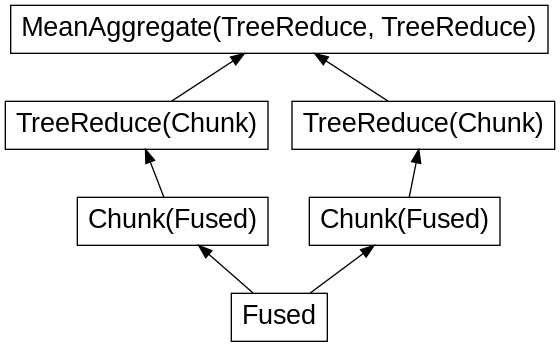

In [ ]:
# Un-optimized vs optimized graph size
g_raw = mean_.__dask_graph__()
print("Tasks in raw graph       :", len(g_raw))
try:
    opt = mean_.optimize()                 # dask-expr: projection pushdown, fusion
    print("Tasks in optimized graph :", len(opt.__dask_graph__()))
except Exception as e:
    (opt,) = dask.optimize(mean_)
    print("Tasks in optimized graph :", len(opt.__dask_graph__()))

# Visualize (needs graphviz; available on Colab)
try:
    try: opt.visualize(filename="graph_mean.png")
    except Exception: dask.visualize(mean_, filename="graph_mean.png", optimize_graph=True)
    from IPython.display import Image; display(Image("graph_mean.png"))
except Exception as e:
    print("Graph drawing skipped:", e)

### Compare execution structure
Computing 4 results **separately** reads the file 4 times; one **combined** `dask.compute(...)` shares the CSV read between all of them (one graph).

In [ ]:
dask.config.set(scheduler="threads")      # multi-threaded

with Profiler() as p_sep:                  # separate -> 4 passes over the file
    a = mean_.compute(); b = sum_.compute(); c = count_.compute(); d = gmean_.compute()
print(f"Separate computes : {p_sep.elapsed:.1f}s | peak {p_sep.peak_mb:.0f} MB")

with Profiler() as p3:                     # combined -> 1 optimized graph
    a, b, c, d = dask.compute(mean_, sum_, count_, gmean_)
print(f"Combined compute  : {p3.elapsed:.1f}s | peak {p3.peak_mb:.0f} MB")
print(f"mean={a:.4f} sum={b:,.0f} rows={c:,}  (pandas chunking mean={r_pd['mean']:.4f})")
results["Dask DataFrame"] = dict(time=p3.elapsed, peak_mb=p3.peak_mb, status="OK")

Separate computes : 337.3s | peak 1966 MB
Combined compute  : 80.9s | peak 1960 MB
mean=19.3777 sum=1,469,056,128 rows=75,811,575  (pandas chunking mean=19.3777)


In [ ]:
# Threads vs processes scheduler
for sched in ["threads", "processes"]:
    with dask.config.set(scheduler=sched), Profiler() as pp:
        dask.compute(mean_, sum_, count_, gmean_)
    print(f"{sched:10s}: {pp.elapsed:.1f}s | peak (incl. workers) {pp.peak_mb:.0f} MB")

threads   : 78.4s | peak (incl. workers) 1932 MB
processes : 100.6s | peak (incl. workers) 2863 MB


In [ ]:

PQ = "/content/big_taxi_parquet"
with Profiler() as pw:
    dd.read_csv(CSV_PATH, blocksize="256MB",
                usecols=["VendorID", "PULocationID", "passenger_count", "trip_distance", "fare_amount", "tip_amount"],
                dtype={"passenger_count": "float32", "trip_distance": "float32", "fare_amount": "float32", "tip_amount": "float32"}
                ).to_parquet(PQ, compression="snappy")
print(f"CSV->Parquet: {pw.elapsed:.1f}s | Parquet size "
      f"{sum(os.path.getsize(os.path.join(PQ,f)) for f in os.listdir(PQ))/1024**3:.2f} GB")
with Profiler() as pq:
    dd.read_parquet(PQ, columns=[VALUE_COL]).mean().compute()
print(f"Mean from Parquet: {pq.elapsed:.1f}s | peak {pq.peak_mb:.0f} MB")

CSV->Parquet: 141.9s | Parquet size 0.71 GB
Mean from Parquet: 3.6s | peak 1325 MB


## 4. Benchmark summary

,time,peak_mb,status,peak_pct_RAM
Standard Pandas,None,3072,OOM (MemoryError),100
Pandas Chunking,89.901498,569.964844,OK,4.392613
Dask DataFrame,80.929098,1959.636719,OK,15.102555


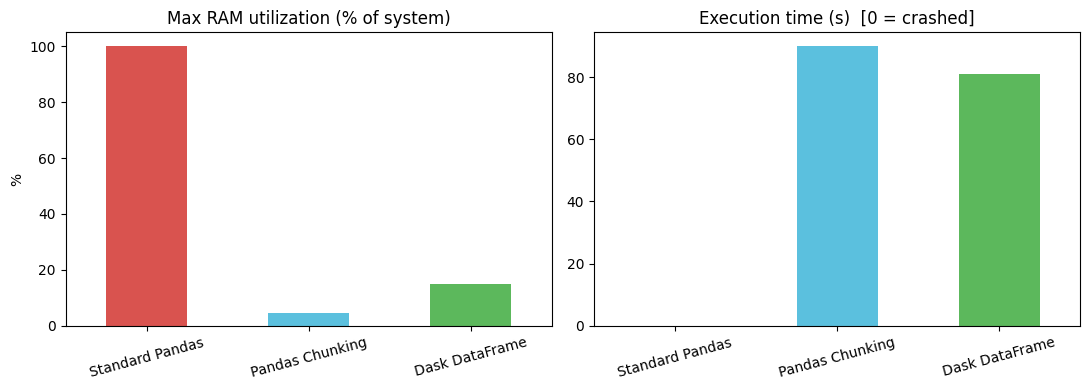

In [ ]:
import matplotlib.pyplot as plt
bench = pd.DataFrame(results).T
bench["peak_pct_RAM"] = bench["peak_mb"] * 1024**2 / TOTAL_RAM * 100
bench.loc["Standard Pandas", "peak_pct_RAM"] = 100
display(bench)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bench["peak_pct_RAM"].plot.bar(ax=ax[0], color=["#d9534f", "#5bc0de", "#5cb85c"])
ax[0].set_title("Max RAM utilization (% of system)"); ax[0].set_ylabel("%"); ax[0].tick_params(axis="x", rotation=15)
t = bench["time"].astype(float).fillna(0)
t.plot.bar(ax=ax[1], color=["#d9534f", "#5bc0de", "#5cb85c"])
ax[1].set_title("Execution time (s)  [0 = crashed]"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("benchmark.png", dpi=150); plt.show()

## 5. Conclusions
| Method | Max RAM | Speed | Why |
|---|---|---|---|
| Standard Pandas | 100% → `MemoryError` | N/A | Loads the whole file; in-memory size is 2–4x the CSV size |
| Pandas chunking | Low, ~constant | Moderate (sequential) | Only one 100k-row chunk + small aggregates in memory; single core |
| Dask DataFrame | Low, bounded by partition size x workers | Fast (parallel) | Lazy graph, optimized (projection/fusion), partitions processed in parallel |

**Key points:** use `usecols` and compact `dtype`s; aggregate incrementally; prefer Parquet over CSV for repeated work; combine results in a single `dask.compute()` call.